# Clustering por atributos y lectura espacial — Siniestros fatales del Perú

**Pregunta:** ¿qué perfiles de siniestros fatales aparecen al agruparlos por gravedad y condiciones vehiculares, y dónde se distribuyen esos perfiles?

Se reproduce el **K-means original de cuatro grupos**. Después se agregan las variables excluidas y las coordenadas para interpretar los resultados, siguiendo la Parte II del laboratorio del miércoles y el uso de GeoPandas del lunes.

## 1. Método y selección de atributos

**K-means es clustering particional, no jerárquico.** Lo elegimos porque resume 9 106 siniestros en grupos interpretables de atributos numéricos preparados. Frente al **jerárquico aglomerativo**, es más sencillo de ejecutar a esta escala; frente a **DBSCAN espacial**, responde a la similitud entre siniestros, no a la concentración de ubicaciones. No presupone que los grupos sean geográficamente contiguos.

Entramos con **10 variables**: fallecidos, lesionados, número de vehículos, edad promedio; proporciones de vehículos con seguro, CITV y fugados; presencia de moto, conductor sin licencia y dosaje positivo.

**Excluimos del entrenamiento:**
- **Clase y causa:** no queremos reproducir categorías oficiales; además, muchas causas siguen en investigación.
- **Zona, peatón involucrado y coordenadas:** se reservan para contrastar los grupos y mapearlos; la ubicación no define la similitud.
- **Personas y conteos por sexo:** parcialmente redundantes con las víctimas y con algunas inconsistencias de registro.
- **Hora y trimestre:** requieren tratar su naturaleza temporal; **red vial:** sus códigos numéricos son categorías, no distancias.

Todas estas columnas permanecen en la matriz para **interpretarlas después**, sin cambiar las etiquetas que genera K-means.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import folium

# Archivo en la misma carpeta que este notebook.
df = pd.read_excel("matriz_analit.xlsx", index_col=0)
print("Matriz:", df.shape)
display(df[["cantidad_de_fallecidos", "cantidad_de_lesionados", "n_vehiculos", "edad_promedio"]].head(3))

Matriz: (9106, 31)


,cantidad_de_fallecidos,cantidad_de_lesionados,n_vehiculos,edad_promedio
0,1,0,1,21.00
1,1,3,1,29.25
2,2,0,1,37.50


## 2. Preparación — misma representación que el notebook original

Las proporciones comparan siniestros con distinto número de vehículos. Aplicamos `log1p` a fallecidos/lesionados, sustituimos dos edades registradas como cero por la mediana y estandarizamos las siete variables numéricas. Las tres binarias permanecen en 0/1.

In [2]:
numericas = ["cantidad_de_fallecidos", "cantidad_de_lesionados", "n_vehiculos",
             "edad_promedio", "prop_seguro", "prop_citv", "prop_fugados"]
binarias = ["existe_moto", "existe_conductor_sin_licencia_vigente",
            "existe_dosaje_cualitativo_positivo"]

X = df[["cantidad_de_fallecidos", "cantidad_de_lesionados", "n_vehiculos",
        "edad_promedio"] + binarias].copy()
X["prop_seguro"] = df["n_con_seguro_vigente"] / df["n_vehiculos"]
X["prop_citv"] = df["n_con_citv_vigente"] / df["n_vehiculos"]
X["prop_fugados"] = df["n_vehiculos_fugados"] / df["n_vehiculos"]
X = X[numericas + binarias]

X.loc[X["edad_promedio"] == 0, "edad_promedio"] = X.loc[
    X["edad_promedio"] > 0, "edad_promedio"].median()
for columna in ["cantidad_de_fallecidos", "cantidad_de_lesionados"]:
    X[columna] = np.log1p(X[columna])
X[numericas] = StandardScaler().fit_transform(X[numericas])
print("Variables utilizadas:", X.shape[1], "| Registros:", len(X))

Variables utilizadas: 10 | Registros: 9106


## 3. Evaluación de K y modelo

Comparamos **inercia** (menor es mejor), **silueta** (mayor es mejor) y **Davies–Bouldin** (menor es mejor). Mantenemos **K = 4**, como en el análisis original, para conservar sus perfiles; no afirmamos que sea el único valor óptimo.

,K,Inercia,Silueta,Davies-Bouldin
0,2,54063.943,0.229,1.746
1,3,46236.438,0.245,1.573
2,4,39938.555,0.247,1.473
3,5,34306.877,0.271,1.447
4,6,30510.445,0.285,1.280
5,7,27733.438,0.289,1.239


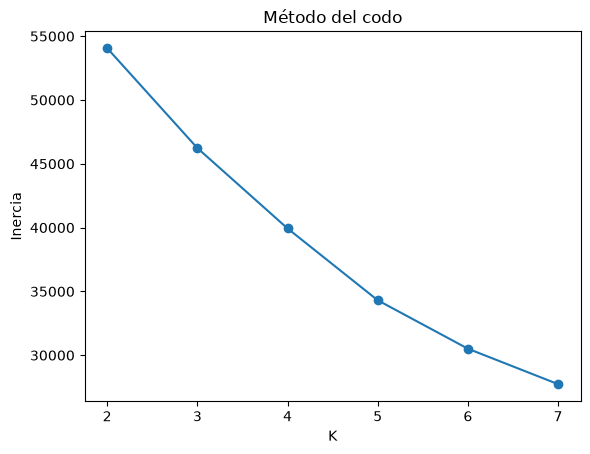

In [3]:
evaluacion = []
for k in range(2, 8):
    m = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    etiquetas = m.fit_predict(X)
    evaluacion.append([k, m.inertia_,
                       silhouette_score(X, etiquetas, sample_size=1500, random_state=42),
                       davies_bouldin_score(X, etiquetas)])

evaluacion = pd.DataFrame(evaluacion, columns=["K", "Inercia", "Silueta", "Davies-Bouldin"])
display(evaluacion.round(3))
plt.plot(evaluacion["K"], evaluacion["Inercia"], "o-")
plt.xlabel("K"); plt.ylabel("Inercia"); plt.title("Método del codo")
plt.show()

In [4]:
modelo = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
df["cluster_kmeans"] = modelo.fit_predict(X)
print("Inercia con K=4:", round(modelo.inertia_, 2))
display(df["cluster_kmeans"].value_counts().sort_index().rename("Siniestros").to_frame())

Inercia con K=4: 39938.56


,Siniestros
cluster_kmeans,
0,1165
1,885
2,3510
3,3546


## 4. Interpretación de los cuatro grupos

Interpretamos con las **variables originales**, no con sus valores estandarizados. Las descripciones se asignan después del algoritmo; los números 0–3 son etiquetas arbitrarias.

In [5]:
perfil_datos = df.assign(
    prop_seguro=df["n_con_seguro_vigente"] / df["n_vehiculos"],
    prop_citv=df["n_con_citv_vigente"] / df["n_vehiculos"],
    prop_fugados=df["n_vehiculos_fugados"] / df["n_vehiculos"])
perfil = perfil_datos.groupby("cluster_kmeans").agg(
    siniestros=("cluster_kmeans", "size"),
    fallecidos_prom=("cantidad_de_fallecidos", "mean"),
    lesionados_prom=("cantidad_de_lesionados", "mean"),
    vehiculos_prom=("n_vehiculos", "mean"),
    edad_prom=("edad_promedio", "mean"),
    seguro_pct=("prop_seguro", "mean"),
    citv_pct=("prop_citv", "mean"),
    fugados_pct=("prop_fugados", "mean"),
    moto_pct=("existe_moto", "mean"),
    sin_licencia_pct=("existe_conductor_sin_licencia_vigente", "mean"),
    dosaje_pct=("existe_dosaje_cualitativo_positivo", "mean"))
perfil.loc[:, perfil.columns.str.endswith("_pct")] *= 100
display(perfil.round(1))

,siniestros,fallecidos_prom,lesionados_prom,vehiculos_prom,edad_prom,seguro_pct,citv_pct,fugados_pct,moto_pct,sin_licencia_pct,dosaje_pct
cluster_kmeans,,,,,,,,,,,
0,1165,2.2,4.8,1.6,35.1,92.4,63.6,0.6,7.3,29.6,5.1
1,885,1.0,0.0,1.0,41.5,0.2,0.1,98.8,0.6,2.5,4.0
2,3510,1.0,0.2,1.4,43.9,97.1,75.7,0.3,18.6,23.7,5.8
3,3546,1.0,0.4,1.4,35.7,34.4,4.4,3.1,59.1,53.9,8.3


**Perfiles obtenidos:**

- **Clúster 0 — Mayor gravedad humana (1 165):** promedia **2,22 fallecidos** y **4,79 lesionados** por siniestro; predominan eventos con múltiples víctimas.
- **Clúster 1 — Fuga vehicular (885):** cerca del **98,8 %** de los vehículos involucrados figuran como fugados, en promedio.
- **Clúster 2 — Mayor cobertura vehicular (3 510):** registra **97,1 %** de vehículos asegurados y **75,7 %** con CITV vigente, en promedio.
- **Clúster 3 — Motocicletas y falta de licencia (3 546):** **59,1 %** de siniestros con motocicletas y **53,9 %** con al menos un conductor sin licencia vigente.

Estas características distinguen **perfiles dentro de siniestros fatales**; no demuestran causalidad ni probabilidad de sufrir un accidente.

## 5. Agregamos las variables excluidas para contrastar los perfiles

El algoritmo **no vuelve a entrenarse**: las clases, causas, zona, peatones y demografía solo describen qué registros quedaron dentro de cada grupo.

In [6]:
excluidas = ["zona_RURAL", "peaton_involucrado", "clase_ATROPELLO",
             "clase_CHOQUE", "clase_DESPISTE", "causa_INVESTIGACION"]
contexto = df.groupby("cluster_kmeans")[excluidas].mean().mul(100)
contexto["personas_prom"] = df.groupby("cluster_kmeans")["n_personas"].mean()
contexto["hombres_prom"] = df.groupby("cluster_kmeans")["n_masculino"].mean()
contexto["mujeres_prom"] = df.groupby("cluster_kmeans")["n_femenino"].mean()
display(contexto.round(1))

# Distribución porcentual de las categorías que tampoco entraron a K-means.
for variable in ["hora_siniestro", "trimestre", "red_vial"]:
    print("Distribución (%) de", variable)
    display((pd.crosstab(df["cluster_kmeans"], df[variable], normalize="index") * 100).round(1))

,zona_RURAL,peaton_involucrado,clase_ATROPELLO,clase_CHOQUE,clase_DESPISTE,causa_INVESTIGACION,personas_prom,hombres_prom,mujeres_prom
cluster_kmeans,,,,,,,,,
0,82.5,4.7,1.2,50.6,44.5,44.0,7.6,4.6,2.9
1,49.8,92.3,92.2,2.8,2.1,76.6,2.0,0.9,0.1
2,52.4,38.2,35.5,36.2,23.1,47.2,2.2,1.8,0.3
3,55.3,20.2,19.2,38.7,34.5,49.6,2.0,1.6,0.3


Distribución (%) de hora_siniestro


hora_siniestro,1,2,3,4
cluster_kmeans,,,,
0,21.8,26.7,28.5,23.0
1,34.5,14.6,9.8,41.1
2,17.1,27.7,26.1,29.1
3,21.3,21.7,22.3,34.6


Distribución (%) de trimestre


trimestre,1,2,3,4
cluster_kmeans,,,,
0,18.4,25.7,25.0,31.0
1,17.3,22.5,29.6,30.6
2,17.1,25.6,26.6,30.6
3,16.9,25.9,24.9,32.2


Distribución (%) de red_vial


red_vial,0,1,2,3,4
cluster_kmeans,,,,,
0,4.4,5.9,11.5,8.8,69.4
1,1.6,21.2,6.8,6.8,63.6
2,2.6,25.7,7.8,7.1,56.8
3,4.8,25.0,13.6,10.1,46.6


**Qué aportan las variables excluidas:**

- **G0:** **82,5 %** en zona rural; al incorporar `clase_*`, aparecen principalmente **choques (50,6 %)** y **despistes (44,5 %)**. La mayor gravedad ya era parte de los atributos de entrenamiento; las clases y la zona son un contraste externo.
- **G1:** **92,2 %** son atropellos y **92,3 %** registran peatones involucrados; **76,6 %** conservan la causa *en investigación*. Se descubre esa asociación sin haber utilizado la clase ni el peatón para formar el grupo.
- **G2:** mezcla **choques (36,2 %)**, **atropellos (35,5 %)** y **despistes (23,1 %)**. Es un perfil de cobertura vehicular, **no** una clase específica de accidente.
- **G3:** prevalecen **choques (38,7 %)** y **despistes (34,5 %)**. Los atributos de moto y licencia ya influyeron en la agrupación; estas clases sirven para contextualizarla.

Las tablas por **hora, trimestre y red vial** muestran cómo se distribuyen sus códigos; no atribuimos significados horarios o viales sin disponer del diccionario de categorías. Los promedios por sexo requieren cautela por inconsistencias de registro.

## 6. Lectura espacial con GeoPandas

Igual que en el laboratorio: `X = longitud`, `Y = latitud` y `EPSG:4326`. **Las coordenadas se agregan después de K-means** para representar los mismos cuatro perfiles, no para construirlos. El archivo `peru_contorno.geojson` contiene un contorno nacional simplificado.

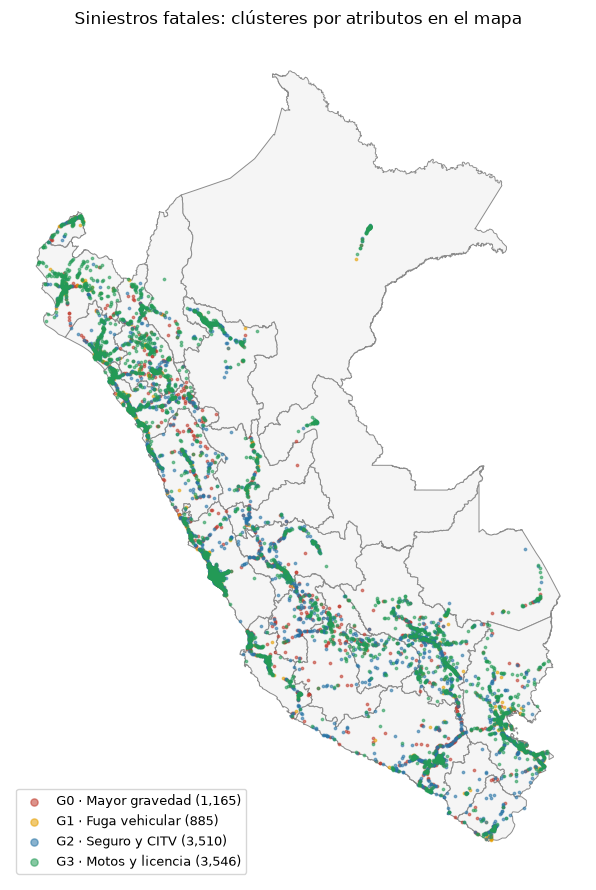

In [7]:
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df["coordenadas_longitud"],
                                    df["coordenadas_latitud"]), crs="EPSG:4326")
peru = gpd.read_file("peru_shapes/per_admbnda_adm1_ign_20200714.shp").to_crs(gdf.crs)
nombres = {0: "G0 · Mayor gravedad", 1: "G1 · Fuga vehicular",
           2: "G2 · Seguro y CITV", 3: "G3 · Motos y licencia"}
colores = {0: "#c0392b", 1: "#e69f00", 2: "#2874a6", 3: "#239b56"}

fig, ax = plt.subplots(figsize=(9, 9))
peru.plot(ax=ax, color="#f5f5f5", edgecolor="#8c8c8c", linewidth=.7)
for k in range(4):
    pts = gdf[gdf["cluster_kmeans"] == k]
    pts.plot(ax=ax, color=colores[k], markersize=3, alpha=.55,
             label=f"{nombres[k]} ({len(pts):,})")
ax.legend(loc="lower left", fontsize=9, markerscale=3, frameon=True)
ax.set_title("Siniestros fatales: clústeres por atributos en el mapa")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("mapa_4_clusters_peru.png", dpi=160)
plt.show()

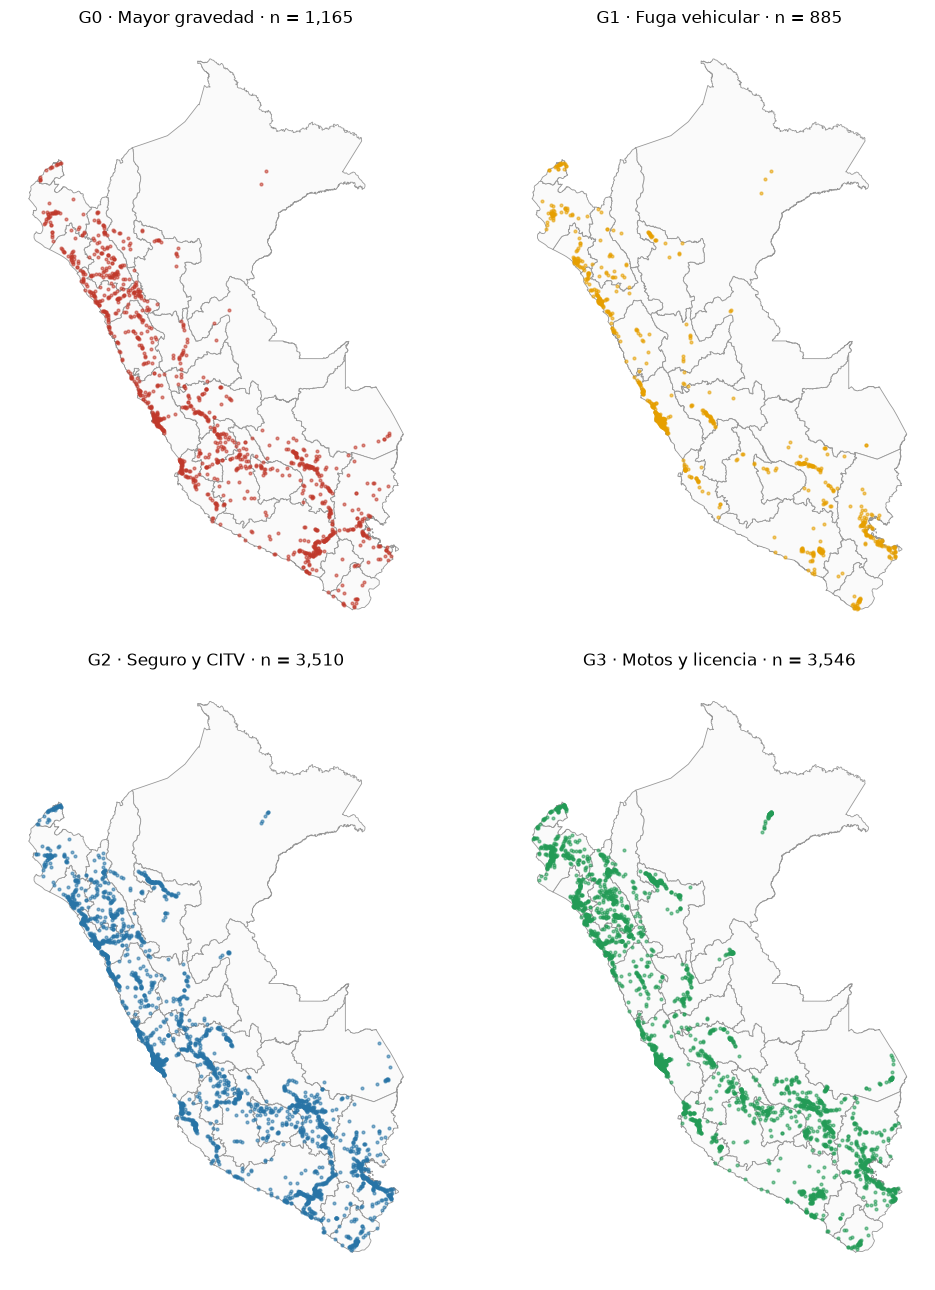

In [8]:
# Un mapa por perfil evita que los puntos de un grupo oculten a otro.
fig, axes = plt.subplots(2, 2, figsize=(11, 13))
for k, ax in enumerate(axes.flat):
    peru.plot(ax=ax, color="#fafafa", edgecolor="#999999", linewidth=.6)
    gdf[gdf["cluster_kmeans"] == k].plot(
        ax=ax, color=colores[k], markersize=4, alpha=.55)
    ax.set_title(f"{nombres[k]} · n = {(df.cluster_kmeans == k).sum():,}")
    ax.set_axis_off()
plt.tight_layout()
plt.savefig("mapas_por_grupo.png", dpi=150)
plt.show()

### Comparación espacial simple

Para cuantificar una diferencia visible en el mapa, dividimos el territorio en **franjas aproximadas de latitud**. **No son departamentos ni regiones administrativas** y no se usaron para entrenar.

In [9]:
franjas = pd.cut(df["coordenadas_latitud"], bins=[-19, -14, -8, -3],
                 labels=["Sur (< -14°)", "Centro (-14° a -8°)", "Norte (> -8°)"])
distribucion = pd.crosstab(df["cluster_kmeans"], franjas, normalize="index") * 100
display(distribucion.round(1))

coordenadas_latitud,Sur (< -14°),Centro (-14° a -8°),Norte (> -8°)
cluster_kmeans,,,
0,26.9,50.1,23.0
1,24.9,54.2,20.9
2,25.8,57.4,16.8
3,20.9,45.2,33.9


**Interpretación espacial:** el grupo **G3** tiene una presencia relativa mayor en la franja norte (**33,9 %**) que **G2 (16,8 %)**. En los cuatro grupos predomina la franja central según estos límites. Los mapas permiten observar dónde aparecen los perfiles, pero **no identifican zonas de mayor riesgo**: faltan medidas de exposición, como tránsito o población, y una delimitación administrativa más detallada.

La ubicación no modificó ningún grupo. Para estudiar *concentraciones físicas* habría que plantear por separado DBSCAN espacial o densidades geográficas.

## Visualización con Folium

## 7. Exportar resultados

Guardamos las etiquetas y la geometría para reproducir los mapas o continuar el análisis en QGIS/GeoPandas.

In [10]:
df.to_csv("siniestros_kmeans_4grupos.csv", index=False)
gdf[["cluster_kmeans", "cantidad_de_fallecidos", "geometry"]].to_file(
    "siniestros_kmeans_4grupos.geojson", driver="GeoJSON")
print("Guardados: CSV, GeoJSON y dos mapas PNG")

Guardados: CSV, GeoJSON y dos mapas PNG
